In [ ]:
import sys
!{sys.executable} -m pip install --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu128 --no-cache-dir

In [1]:
import torch
print("Version:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("cuDNN:", torch.backends.cudnn.version())
print("Available:", torch.cuda.is_available())
print("Device count:", torch.cuda.device_count())
print("Name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "—")

Version: 2.11.0+cu128
CUDA build: 12.8
cuDNN: 91900
Available: True
Device count: 1
Name: NVIDIA GeForce RTX 3050 Laptop GPU


In [ ]:
!pip install opencv-python matplotlib numpy tqdm albumentations
import cv2
import matplotlib.pyplot as plt
import numpy as np
import os
from tqdm import tqdm

import albumentations as A
from albumentations.pytorch import ToTensorV2

import torch
import torch.nn as nn
import torch.nn.functional as F

In [5]:
class CNA(nn.Module):
    def __init__(self, in_nc, out_nc, stride=1):
        super().__init__()
        self.conv = nn.Conv2d(in_nc, out_nc, 3, stride=stride, padding=1, bias=False)
        self.norm = nn.BatchNorm2d(out_nc)
        self.act = nn.GELU()

    def forward(self, x):
        return self.act(self.norm(self.conv(x)))

class UnetBlock(nn.Module):
    def __init__(self, in_nc, inner_nc, out_nc, inner_block=None):
        super().__init__()
        self.conv1 = CNA(in_nc, inner_nc, stride=2)
        self.conv2 = CNA(inner_nc, inner_nc)
        self.inner_block = inner_block
        self.conv3 = CNA(inner_nc, inner_nc)
        self.conv_cat = nn.Conv2d(inner_nc + in_nc, out_nc, 3, padding=1)

    def forward(self, x):
        _, _, h, w = x.shape
        inner = self.conv1(x)
        inner = self.conv2(inner)
        if self.inner_block is not None:
            inner = self.inner_block(inner)
        inner = self.conv3(inner)
        inner = F.interpolate(inner, size=(h, w), mode='bilinear', align_corners=False)
        inner = torch.cat((x, inner), axis=1)
        return self.conv_cat(inner)

class Unet(nn.Module):
    def __init__(self, in_nc=3, nc=32, out_nc=1, num_downs=5):
        super().__init__()
        self.cna1 = CNA(in_nc, nc)
        self.cna2 = CNA(nc, nc)

        unet_block = None
        for i in range(num_downs - 3):
            unet_block = UnetBlock(8 * nc, 8 * nc, 8 * nc, unet_block)
        unet_block = UnetBlock(4 * nc, 8 * nc, 4 * nc, unet_block)
        unet_block = UnetBlock(2 * nc, 4 * nc, 2 * nc, unet_block)
        self.unet_block = UnetBlock(nc, 2 * nc, nc, unet_block)

        self.cna3 = CNA(nc, nc)
        self.conv_last = nn.Conv2d(nc, out_nc, 3, padding=1)

    def forward(self, x):
        out = self.cna2(self.cna1(x))
        out = self.unet_block(out)
        out = self.cna3(out)
        return self.conv_last(out)

In [7]:
class MyDataset(torch.utils.data.Dataset):
    def __init__(self, images_directory, masks_directory, transform=None):
        self.images_directory = images_directory
        self.masks_directory = masks_directory
        self.transform = transform
        self.images_filenames = sorted(os.listdir(self.images_directory))

    def __len__(self):
        return len(self.images_filenames)

    def __getitem__(self, idx):
        fname = self.images_filenames[idx]
        image = cv2.imread(os.path.join(self.images_directory, fname), cv2.IMREAD_COLOR)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(os.path.join(self.masks_directory, fname), cv2.IMREAD_GRAYSCALE)

        image = image.astype(np.float32) / 255.0
        mask = mask.astype(np.float32) / 255.0

        if self.transform is not None:
            t = self.transform(image=image, mask=mask)
            image = t["image"]
            mask = t["mask"]

        if not isinstance(mask, torch.Tensor):
            mask = torch.from_numpy(mask)
        if mask.ndim == 2:
            mask = mask.unsqueeze(0)

        return image, mask

In [ ]:
train_transform = A.Compose([
    A.PadIfNeeded(min_height=256, min_width=256),
    A.RandomCrop(256, 256),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.05, rotate_limit=15, p=0.5),
    ToTensorV2(),
])

val_transform = A.Compose([
    A.PadIfNeeded(min_height=256, min_width=256),
    A.CenterCrop(256, 256),
    ToTensorV2(),
])

ds_train = MyDataset('./segmentation_full_body_mads_dataset_1192_img/images', './segmentation_full_body_mads_dataset_1192_img/masks', transform=train_transform)
ds_val   = MyDataset('./segmentation_full_body_mads_dataset_1192_img/images', './segmentation_full_body_mads_dataset_1192_img/masks', transform=val_transform)

train_loader = torch.utils.data.DataLoader(
    ds_train, shuffle=True, batch_size=16,
    num_workers=0,        # ← изменено на 0
    pin_memory=True,
    drop_last=True,
)

In [13]:
from torch.amp import autocast, GradScaler

def dice_loss(pred_logits, target, eps=1e-6):
    pred = torch.sigmoid(pred_logits)
    intersection = (pred * target).sum(dim=(1, 2, 3))
    union = pred.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return (1 - (2 * intersection + eps) / (union + eps)).mean()

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {device}')

model = Unet(in_nc=3, nc=32, out_nc=1, num_downs=5).to(device)
bce = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.97)
scaler = GradScaler('cuda')

epochs = 50
for epoch in range(epochs):
    model.train()
    loss_sum = 0.0
    for img, mask in tqdm(train_loader, desc=f'epoch {epoch+1}/{epochs}'):
        img = img.to(device, non_blocking=True)
        mask = mask.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with autocast('cuda'):
            pred = model(img)
            loss = 0.5 * bce(pred, mask) + 0.5 * dice_loss(pred, mask)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        loss_sum += loss.item()

    scheduler.step()
    print(f'epoch {epoch+1}: loss={loss_sum/len(train_loader):.5f} lr={scheduler.get_last_lr()[0]:.6f}')

    if (epoch + 1) % 10 == 0:
        torch.save(model.state_dict(), f'unet_epoch{epoch+1}.pth')

torch.save(model.state_dict(), 'unet_final.pth')
print('Готово: unet_final.pth')

Device: cuda


epoch 1/50: 100%|██████████| 74/74 [00:33<00:00,  2.19it/s]


epoch 1: loss=0.40064 lr=0.000970


epoch 2/50: 100%|██████████| 74/74 [00:30<00:00,  2.40it/s]


epoch 2: loss=0.17789 lr=0.000941


epoch 3/50: 100%|██████████| 74/74 [00:30<00:00,  2.42it/s]


... (91 outputs left out)

epoch 49/50: 100%|██████████| 74/74 [00:31<00:00,  2.37it/s]


epoch 49: loss=0.07995 lr=0.000225


epoch 50/50: 100%|██████████| 74/74 [00:33<00:00,  2.24it/s]

epoch 50: loss=0.07888 lr=0.000218
Готово: unet_final.pth


In [ ]:
model.eval()
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
idxs = [0, 100, 500]

with torch.no_grad():
    for row, idx in enumerate(idxs):
        img_tensor, true_mask = ds_val[idx]
        img_in = img_tensor.unsqueeze(0).to(device)
        pred = torch.sigmoid(model(img_in))[0, 0].cpu().numpy()
        img_np = img_tensor.permute(1, 2, 0).cpu().numpy()

        axes[row, 0].imshow(img_np)
        axes[row, 0].set_title(f'Фото {idx}')
        axes[row, 0].axis('off')

        axes[row, 1].imshow(pred > 0.5, cmap='gray')
        axes[row, 1].set_title('Предсказание')
        axes[row, 1].axis('off')

        axes[row, 2].imshow(img_np)
        axes[row, 2].imshow(pred > 0.5, alpha=0.5, cmap='Reds')
        axes[row, 2].set_title('Наложение')
        axes[row, 2].axis('off')

plt.tight_layout()
plt.savefig('result.png', dpi=100)
plt.show()

In [15]:
model.eval()
ious = []
with torch.no_grad():
    for img, mask in torch.utils.data.DataLoader(ds_val, batch_size=8, num_workers=0):
        img = img.to(device)
        mask = mask.to(device)
        pred = (torch.sigmoid(model(img)) > 0.5).float()
        inter = (pred * mask).sum(dim=(1,2,3))
        union = pred.sum(dim=(1,2,3)) + mask.sum(dim=(1,2,3)) - inter
        ious.append((inter + 1e-6) / (union + 1e-6))

iou = torch.cat(ious).mean().item()
print(f"Val IoU: {iou:.4f}")

Val IoU: 0.9263


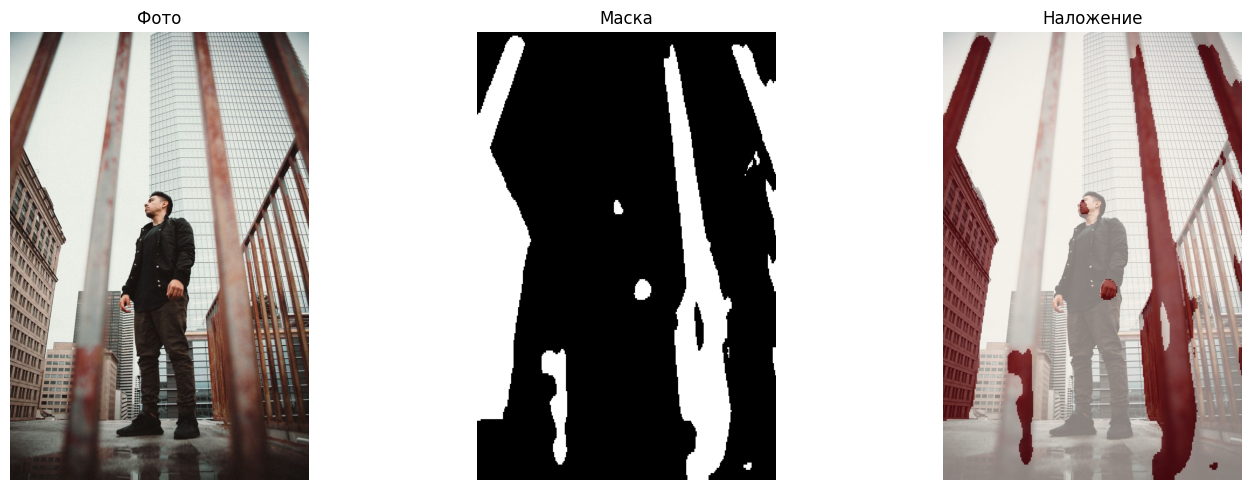

In [ ]:
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt

#1. Путь к фото
image_path = 'photo.jpg'
model_path = 'unet_final.pth'

device = 'cuda' if torch.cuda.is_available() else 'cpu'

#2. Загрузка модели
model = Unet(in_nc=3, nc=32, out_nc=1, num_downs=5).to(device)
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()

#3.Чтение и подготовка
img_bgr = cv2.imread(image_path, cv2.IMREAD_COLOR)
if img_bgr is None:
    raise FileNotFoundError(f"Не удалось открыть: {image_path}")

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_float = img_rgb.astype(np.float32) / 255.0
orig_h, orig_w = img_float.shape[:2]

img_t = cv2.resize(img_float, (256, 256), interpolation=cv2.INTER_LINEAR)
img_t = torch.from_numpy(img_t).permute(2, 0, 1).float().unsqueeze(0).to(device)

#4.Инференс
with torch.no_grad():
    pred = torch.sigmoid(model(img_t))[0, 0].cpu().numpy()

mask_small = (pred > 0.5).astype(np.uint8) * 255
mask_full = cv2.resize(mask_small, (orig_w, orig_h), interpolation=cv2.INTER_NEAREST)

#5. Вывод на экран
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img_rgb)
axes[0].set_title('Фото')
axes[0].axis('off')

axes[1].imshow(mask_full, cmap='gray')
axes[1].set_title('Маска')
axes[1].axis('off')

axes[2].imshow(img_rgb)
axes[2].imshow(mask_full > 0, alpha=0.5, cmap='Reds')
axes[2].set_title('Наложение')
axes[2].axis('off')

plt.tight_layout()
plt.show()